# **1. Perkenalan Dataset**


Tahap pertama, Anda harus mencari dan menggunakan dataset dengan ketentuan sebagai berikut:

1. **Sumber Dataset**:  
   Dataset dapat diperoleh dari berbagai sumber, seperti public repositories (*Kaggle*, *UCI ML Repository*, *Open Data*) atau data primer yang Anda kumpulkan sendiri.


**Dataset yang digunakan: Beijing Multi-Site Air Quality**

- **Sumber:** [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/501/beijing+multi+site+air+quality+data)
- **Periode:** 1 Maret 2013 sampai 28 Februari 2017, dicatat per jam
- **Jumlah data:** 420.768 baris dari 12 stasiun pemantau kualitas udara di Beijing
- **Tujuan:** memprediksi konsentrasi PM2.5 pada jam berikutnya (time series forecasting)

**Penjelasan kolom:**

| Kolom | Arti | Catatan |
|---|---|---|
| `No` | Nomor baris | Hanya urutan, tidak dipakai sebagai fitur |
| `year`, `month`, `day`, `hour` | Waktu pengukuran | Digabung menjadi satu kolom datetime |
| `PM2.5` | Konsentrasi partikel halus berukuran 2,5 mikrometer ke bawah (ug/m³) | Target prediksi |
| `PM10` | Konsentrasi partikel berukuran 10 mikrometer ke bawah (ug/m³) | |
| `SO2` | Konsentrasi sulfur dioksida (ug/m³) | |
| `NO2` | Konsentrasi nitrogen dioksida (ug/m³) | |
| `CO` | Konsentrasi karbon monoksida (ug/m³) | |
| `O3` | Konsentrasi ozon permukaan (ug/m³) | |
| `TEMP` | Suhu udara (°C) | |
| `PRES` | Tekanan udara (hPa) | |
| `DEWP` | Titik embun (°C) | |
| `RAIN` | Curah hujan per jam (mm) | |
| `wd` | Arah angin, misalnya `N`, `NNW`, `NW` | Kategorikal |
| `WSPM` | Kecepatan angin (m/s) | |
| `station` | Nama stasiun pemantau | 12 stasiun |

# **2. Import Library**

Pada tahap ini, Anda perlu mengimpor beberapa pustaka (library) Python yang dibutuhkan untuk analisis data dan pembangunan model machine learning atau deep learning.

In [1]:
import glob                       # Mencari banyak file CSV sekaligus dengan pola nama
import numpy as np                # Operasi numerik untuk EDA dan preprocessing
import pandas as pd               # Membaca dan mengolah data tabular dari CSV
import matplotlib.pyplot as plt   # Membuat grafik untuk EDA
import seaborn as sns             # Grafik statistik yang lebih ringkas, misalnya heatmap korelasi

# **3. Memuat Dataset**

Pada tahap ini, Anda perlu memuat dataset ke dalam notebook. Jika dataset dalam format CSV, Anda bisa menggunakan pustaka pandas untuk membacanya. Pastikan untuk mengecek beberapa baris awal dataset untuk memahami strukturnya dan memastikan data telah dimuat dengan benar.

Jika dataset berada di Google Drive, pastikan Anda menghubungkan Google Drive ke Colab terlebih dahulu. Setelah dataset berhasil dimuat, langkah berikutnya adalah memeriksa kesesuaian data dan siap untuk dianalisis lebih lanjut.

Jika dataset berupa unstructured data, silakan sesuaikan dengan format seperti kelas Machine Learning Pengembangan atau Machine Learning Terapan

In [2]:
!wget -q -O beijing_air_quality.zip "https://archive.ics.uci.edu/static/public/501/beijing+multi+site+air+quality+data.zip"   # Unduh arsip dataset dari halaman resmi UCI
!unzip -o -q beijing_air_quality.zip -d beijing_air_quality_raw                                                                   # Ekstrak arsip luar, isinya masih berupa zip lagi
!unzip -o -q beijing_air_quality_raw/PRSA2017_Data_20130301-20170228.zip -d beijing_air_quality_raw                             # Ekstrak arsip dalam yang berisi CSV per stasiun

list_file = sorted(glob.glob("beijing_air_quality_raw/**/PRSA_Data_*.csv", recursive=True))   # Ambil 12 file CSV stasiun saja, file lain di arsip tidak ikut
print("Jumlah file:", len(list_file))                                                           # Pastikan jumlahnya 12, sesuai jumlah stasiun

df = pd.concat([pd.read_csv(path_file) for path_file in list_file], ignore_index=True)   # Gabungkan 12 stasiun jadi satu DataFrame, index dibuat ulang agar tidak dobel
print(df.shape)   # Cek jumlah baris dan kolom, seharusnya 420.768 baris
df.head()         # Lihat beberapa baris awal untuk memahami struktur kolom

Jumlah file: 12
(420768, 18)


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin


# **4. Exploratory Data Analysis (EDA)**

Pada tahap ini, Anda akan melakukan **Exploratory Data Analysis (EDA)** untuk memahami karakteristik dataset.

Tujuan dari EDA adalah untuk memperoleh wawasan awal yang mendalam mengenai data dan menentukan langkah selanjutnya dalam analisis atau pemodelan.

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 420768 entries, 0 to 420767
Data columns (total 18 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   No       420768 non-null  int64  
 1   year     420768 non-null  int64  
 2   month    420768 non-null  int64  
 3   day      420768 non-null  int64  
 4   hour     420768 non-null  int64  
 5   PM2.5    412029 non-null  float64
 6   PM10     414319 non-null  float64
 7   SO2      411747 non-null  float64
 8   NO2      408652 non-null  float64
 9   CO       400067 non-null  float64
 10  O3       407491 non-null  float64
 11  TEMP     420370 non-null  float64
 12  PRES     420375 non-null  float64
 13  DEWP     420365 non-null  float64
 14  RAIN     420378 non-null  float64
 15  wd       418946 non-null  object 
 16  WSPM     420450 non-null  float64
 17  station  420768 non-null  object 
dtypes: float64(11), int64(5), object(2)
memory usage: 57.8+ MB


In [4]:
df.isnull().sum()

,0
No,0
year,0
month,0
day,0
hour,0
PM2.5,8739
PM10,6449
SO2,9021
NO2,12116
CO,20701


In [5]:
df['station'].value_counts()

,count
station,
Aotizhongxin,35064
Changping,35064
Dingling,35064
Dongsi,35064
Guanyuan,35064
Gucheng,35064
Huairou,35064
Nongzhanguan,35064
Shunyi,35064


In [6]:
df.describe()

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,WSPM
count,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,412029.000000,414319.000000,411747.000000,408652.000000,400067.000000,407491.000000,420370.000000,420375.000000,420365.000000,420378.000000,420450.000000
mean,17532.500000,2014.662560,6.522930,15.729637,11.500000,79.793428,104.602618,15.830835,50.638586,1230.766454,57.372271,13.538976,1010.746982,2.490822,0.064476,1.729711
std,10122.116943,1.177198,3.448707,8.800102,6.922195,80.822391,91.772426,21.650603,35.127912,1160.182716,56.661607,11.436139,10.474055,13.793847,0.821004,1.246386
min,1.000000,2013.000000,1.000000,1.000000,0.000000,2.000000,2.000000,0.285600,1.026500,100.000000,0.214200,-19.900000,982.400000,-43.400000,0.000000,0.000000
25%,8766.750000,2014.000000,4.000000,8.000000,5.750000,20.000000,36.000000,3.000000,23.000000,500.000000,11.000000,3.100000,1002.300000,-8.900000,0.000000,0.900000
50%,17532.500000,2015.000000,7.000000,16.000000,11.500000,55.000000,82.000000,7.000000,43.000000,900.000000,45.000000,14.500000,1010.400000,3.100000,0.000000,1.400000
75%,26298.250000,2016.000000,10.000000,23.000000,17.250000,111.000000,145.000000,20.000000,71.000000,1500.000000,82.000000,23.300000,1019.000000,15.100000,0.000000,2.200000
max,35064.000000,2017.000000,12.000000,31.000000,23.000000,999.000000,999.000000,500.000000,290.000000,10000.000000,1071.000000,41.600000,1042.800000,29.100000,72.500000,13.200000


In [7]:
#cek kolom dugaan batas alat dalam menhitung batas atas dari variable
for kolom in ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3"]:   # Hanya kolom polutan yang dicek
    nilai_max = df[kolom].max()                              # Nilai tertinggi di kolom tersebut
    jumlah = (df[kolom] == nilai_max).sum()                  # Banyak baris yang nilainya persis sama dengan max
    print(kolom, nilai_max, jumlah)

PM2.5 999.0 1
PM10 999.0 3
SO2 500.0 3
NO2 290.0 1
CO 10000.0 56
O3 1071.0 14


In [8]:
idx = df.index[df["PM2.5"] == 999][0]                                    # Posisi baris yang PM2.5-nya 999
print(df.loc[idx-3:idx+3, ["year", "month", "day", "hour", "station", "PM2.5"]])   # Tampilkan 3 jam sebelum dan sesudahnya
print(df[df["O3"] == 1071][["year", "month", "day", "hour", "station"]])           # Lihat kapan dan di stasiun mana O3 bernilai 1071

        year  month  day  hour        station  PM2.5
411479  2016      2    7    23  Wanshouxigong  171.0
411480  2016      2    8     0  Wanshouxigong  238.0
411481  2016      2    8     1  Wanshouxigong  826.0
411482  2016      2    8     2  Wanshouxigong  999.0
411483  2016      2    8     3  Wanshouxigong  857.0
411484  2016      2    8     4  Wanshouxigong  748.0
411485  2016      2    8     5  Wanshouxigong  662.0
        year  month  day  hour station
109223  2013      8   15    23  Dongsi
109224  2013      8   16     0  Dongsi
109241  2013      8   16    17  Dongsi
109242  2013      8   16    18  Dongsi
109243  2013      8   16    19  Dongsi
109244  2013      8   16    20  Dongsi
109245  2013      8   16    21  Dongsi
109246  2013      8   16    22  Dongsi
109247  2013      8   16    23  Dongsi
109248  2013      8   17     0  Dongsi
109249  2013      8   17     1  Dongsi
109250  2013      8   17     2  Dongsi
109251  2013      8   17     3  Dongsi
109252  2013      8   17     4

In [9]:
#menghitung interpolasi dari datset
data_stasiun = df[df["station"] == "Aotizhongxin"]["PM2.5"]

panjang_sekarang = 0
gaps = []

for nilai in data_stasiun:
  if pd.isna(nilai):
    panjang_sekarang += 1
    continue
  elif panjang_sekarang>0:
    gaps.append(panjang_sekarang)
    panjang_sekarang = 0
if panjang_sekarang > 0:
  gaps.append(panjang_sekarang)

print("Jumlah gaps:", len(gaps))                          # Di sini len() tepat, karena menghitung banyaknya celah
print("gaps terpanjang:", max(gaps, default=0), "jam")   # default=0 mencegah error kalau stasiun ini tidak punya celah sama sekali

Jumlah gaps: 209
gaps terpanjang: 343 jam


In [10]:
kolom_dicek = ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3", "TEMP", "PRES", "DEWP", "RAIN", "WSPM", "wd"]   # Semua kolom yang ada data bolongnya

def hitung_gaps(data):                       # Logikanya sama dengan loop lu sebelumnya, cuma dijadikan fungsi biar bisa dipakai ulang
    panjang_sekarang = 0
    gaps = []
    for nilai in data:
        if pd.isna(nilai):
            panjang_sekarang += 1
        elif panjang_sekarang > 0:
            gaps.append(panjang_sekarang)
            panjang_sekarang = 0
    if panjang_sekarang > 0:
        gaps.append(panjang_sekarang)
    return gaps

ringkasan = []
for kolom in kolom_dicek:
    semua_gaps = []
    for stasiun in df["station"].unique():                              # Dihitung per stasiun, biar gap stasiun satu nggak nyambung ke stasiun lain
        semua_gaps += hitung_gaps(df[df["station"] == stasiun][kolom])
    ringkasan.append({
        "kolom": kolom,
        "jumlah_gap": len(semua_gaps),
        "gap_<=24_jam": sum(1 for gap in semua_gaps if gap <= 24),      # Gap pendek, masih aman diinterpolasi
        "gap_>24_jam": sum(1 for gap in semua_gaps if gap > 24),        # Gap panjang, perlu cara lain
        "gap_terlama_jam": max(semua_gaps, default=0),
    })

pd.DataFrame(ringkasan)

,kolom,jumlah_gap,gap_<=24_jam,gap_>24_jam,gap_terlama_jam
0,PM2.5,2837,2800,37,343
1,PM10,2321,2296,25,343
2,SO2,2846,2801,45,457
3,NO2,3743,3695,48,900
4,CO,4767,4692,75,1517
5,O3,4550,4501,49,497
6,TEMP,234,234,0,7
7,PRES,235,235,0,7
8,DEWP,237,237,0,7
9,RAIN,238,238,0,6


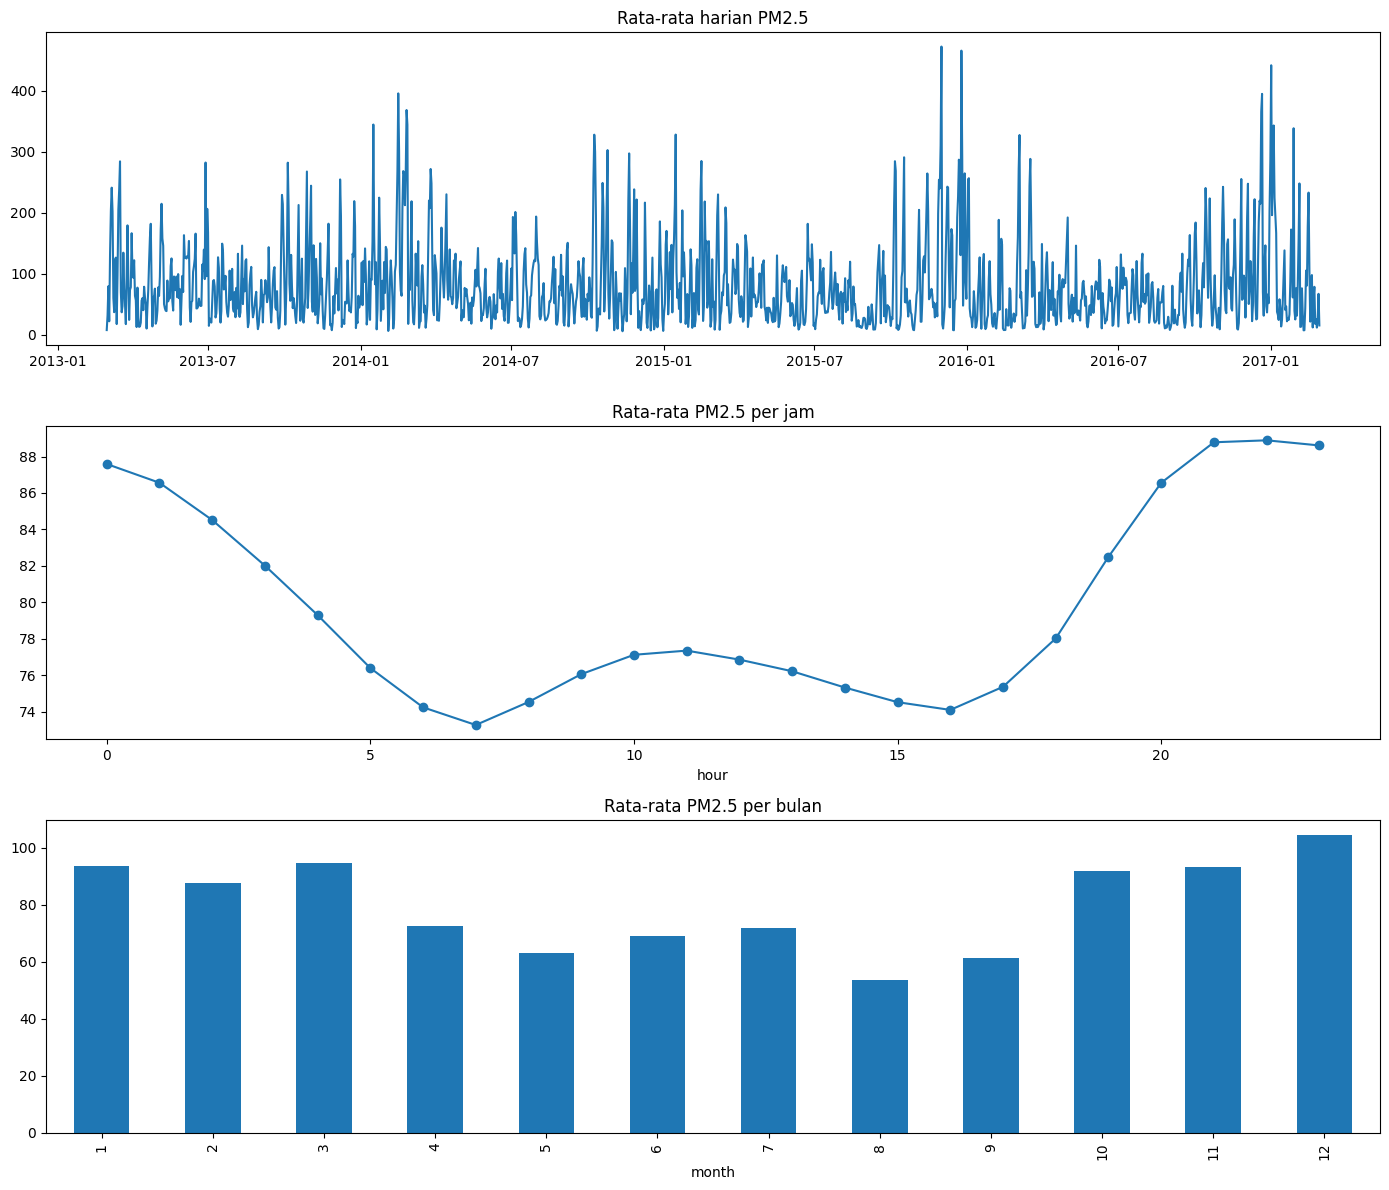

In [11]:
waktu = pd.to_datetime(df[["year", "month", "day", "hour"]])   # Gabung kolom waktu jadi datetime, df aslinya nggak diubah

fig, axes = plt.subplots(3, 1, figsize=(14, 12))

df.groupby(waktu.dt.date)["PM2.5"].mean().plot(ax=axes[0])   # Rata-rata harian, biar tren 4 tahunnya kelihatan
axes[0].set_title("Rata-rata harian PM2.5")

df.groupby("hour")["PM2.5"].mean().plot(ax=axes[1], marker="o")   # Jam berapa PM2.5 biasanya tinggi
axes[1].set_title("Rata-rata PM2.5 per jam")

df.groupby("month")["PM2.5"].mean().plot(kind="bar", ax=axes[2])   # Bulan apa PM2.5 biasanya tinggi
axes[2].set_title("Rata-rata PM2.5 per bulan")

plt.tight_layout()
plt.show()

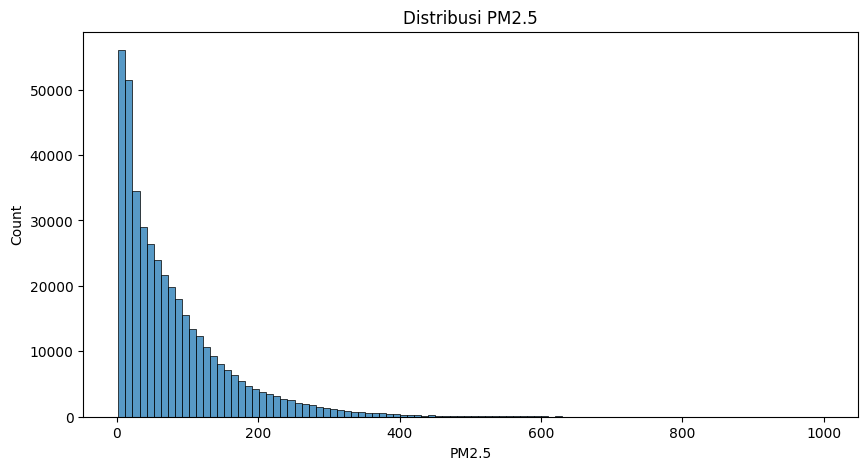

In [12]:
plt.figure(figsize=(10, 5))
sns.histplot(df["PM2.5"].dropna(), bins=100)   # NaN dibuang dulu karena nggak bisa digambar
plt.title("Distribusi PM2.5")
plt.show()

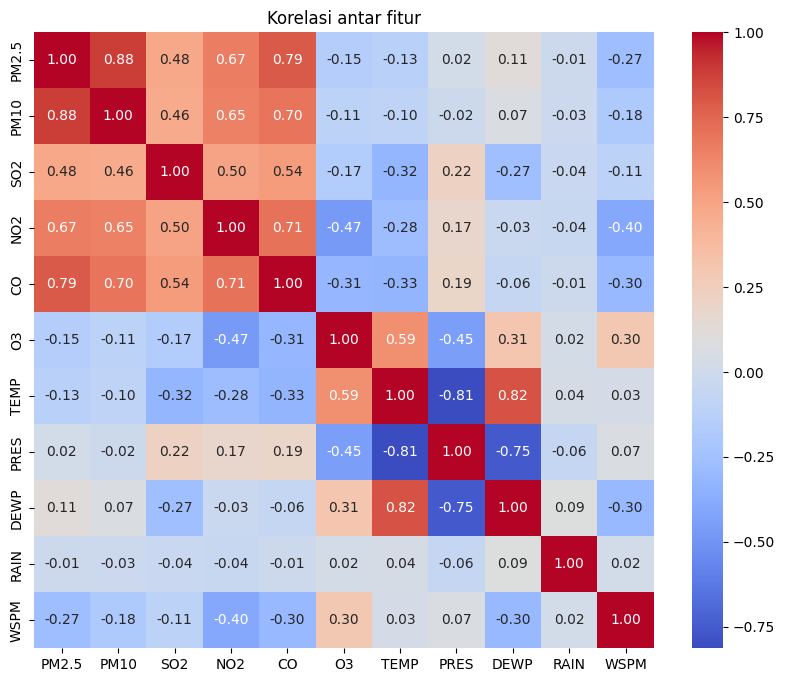

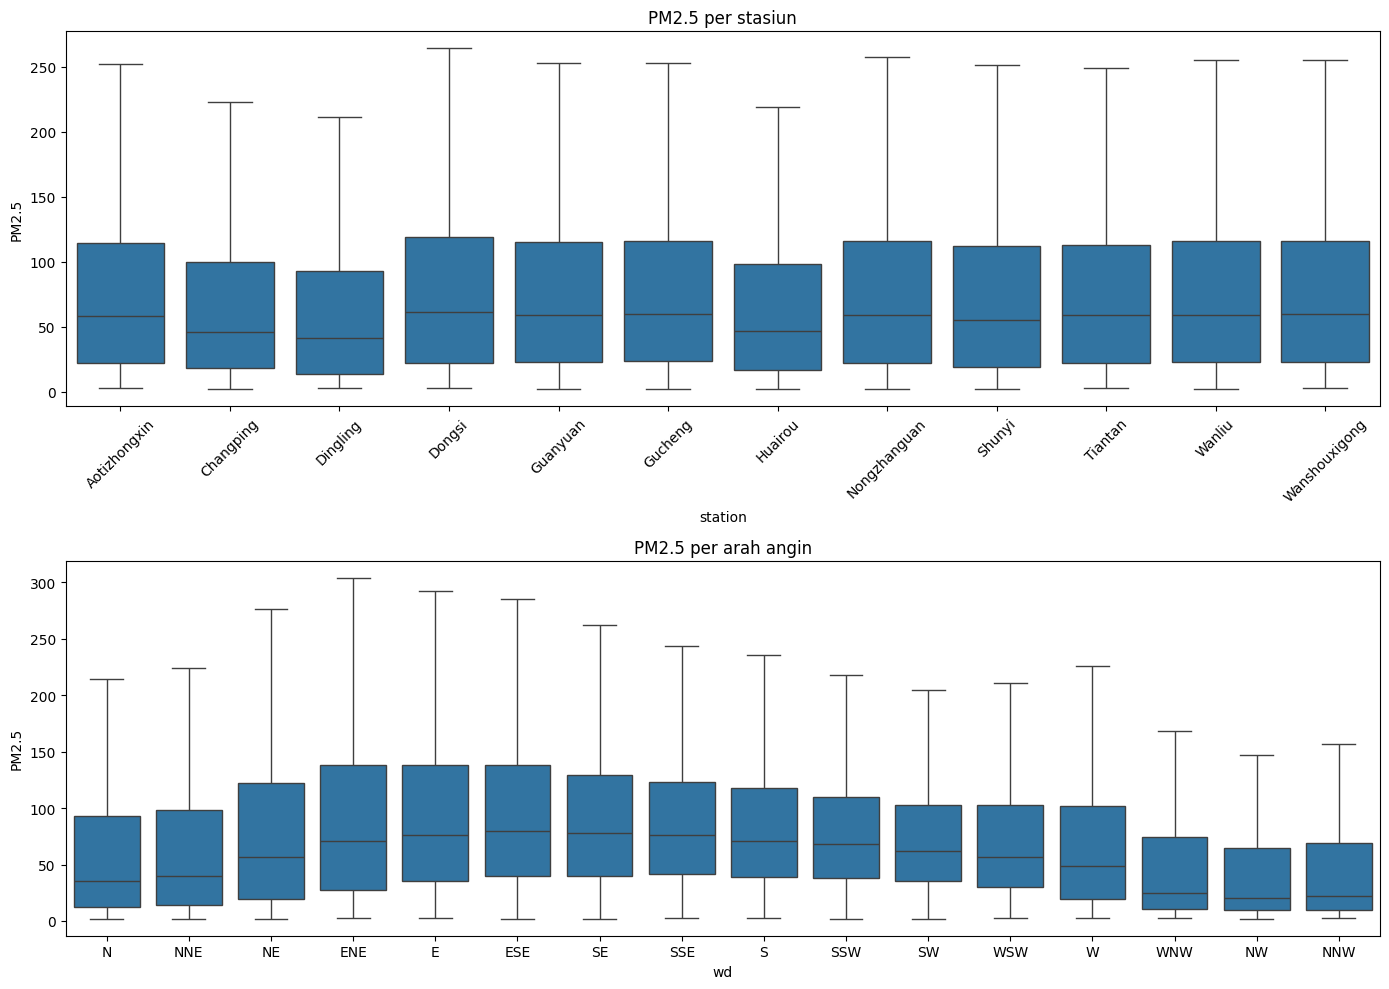

In [13]:
kolom_numerik = ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3", "TEMP", "PRES", "DEWP", "RAIN", "WSPM"]

plt.figure(figsize=(10, 8))
sns.heatmap(df[kolom_numerik].corr(), annot=True, fmt=".2f", cmap="coolwarm")   # Makin dekat ke 1 atau -1, makin kuat hubungannya
plt.title("Korelasi antar fitur")
plt.show()

urutan_arah = ["N", "NNE", "NE", "ENE", "E", "ESE", "SE", "SSE", "S", "SSW", "SW", "WSW", "W", "WNW", "NW", "NNW"]   # Diurutkan searah jarum jam biar gampang dibaca

fig, axes = plt.subplots(2, 1, figsize=(14, 10))

sns.boxplot(data=df, x="station", y="PM2.5", showfliers=False, ax=axes[0])   # showfliers=False biar kotaknya nggak ketutup titik ekstrem
axes[0].set_title("PM2.5 per stasiun")
axes[0].tick_params(axis="x", rotation=45)

sns.boxplot(data=df, x="wd", y="PM2.5", order=urutan_arah, showfliers=False, ax=axes[1])
axes[1].set_title("PM2.5 per arah angin")

plt.tight_layout()
plt.show()

# **5. Data Preprocessing**

Pada tahap ini, data preprocessing adalah langkah penting untuk memastikan kualitas data sebelum digunakan dalam model machine learning.

Jika Anda menggunakan data teks, data mentah sering kali mengandung nilai kosong, duplikasi, atau rentang nilai yang tidak konsisten, yang dapat memengaruhi kinerja model. Oleh karena itu, proses ini bertujuan untuk membersihkan dan mempersiapkan data agar analisis berjalan optimal.

Berikut adalah tahapan-tahapan yang bisa dilakukan, tetapi **tidak terbatas** pada:
1. Menghapus atau Menangani Data Kosong (Missing Values)
2. Menghapus Data Duplikat
3. Normalisasi atau Standarisasi Fitur
4. Deteksi dan Penanganan Outlier
5. Encoding Data Kategorikal
6. Binning (Pengelompokan Data)

Cukup sesuaikan dengan karakteristik data yang kamu gunakan yah. Khususnya ketika kami menggunakan data tidak terstruktur.

In [14]:
import os                                          # Buat bikin folder hasil preprocessing
import joblib                                      # Buat nyimpen scaler, nanti dipakai lagi pas inference
from sklearn.preprocessing import StandardScaler   # Buat scaling fitur numerik

In [15]:
df_bersih = df.copy()   # Kerja di salinan, df asli tetap utuh

df_bersih["datetime"] = pd.to_datetime(df_bersih[["year", "month", "day", "hour"]])   # Gabung kolom waktu jadi satu
df_bersih = df_bersih.drop(columns=["No", "year", "month", "day", "hour"])              # No cuma nomor baris, kolom waktu udah diwakili datetime
df_bersih = df_bersih.sort_values(["station", "datetime"]).reset_index(drop=True)       # Urut per stasiun lalu per jam, wajib buat interpolasi dan windowing

print("Jumlah duplikat:", df_bersih.duplicated(subset=["station", "datetime"]).sum())   # Satu stasiun nggak boleh punya dua data di jam yang sama
df_bersih = df_bersih.drop_duplicates(subset=["station", "datetime"])

Jumlah duplikat: 0


In [16]:
df_bersih.loc[df_bersih["O3"] == 1071, "O3"] = np.nan   # 1071 muncul belasan jam berturut-turut di Dongsi, tanda sensor nyangkut, jadi dianggap data bolong

In [17]:
kolom_numerik = ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3", "TEMP", "PRES", "DEWP", "RAIN", "WSPM"]

df_bersih[kolom_numerik] = df_bersih.groupby("station")[kolom_numerik].transform(
    lambda kolom: kolom.interpolate(method="linear").ffill().bfill())   # Interpolasi per stasiun. ffill dan bfill buat jam kosong di awal atau akhir data yang nggak punya tetangga

df_bersih["wd"] = df_bersih.groupby("station")["wd"].transform(
    lambda kolom: kolom.ffill().bfill())   # Arah angin berupa teks, jadi diisi pakai arah di jam sebelumnya

print("Sisa data bolong:", df_bersih.isnull().sum().sum())   # Harusnya 0

Sisa data bolong: 0


In [18]:
derajat_arah_angin = {"N": 0, "NNE": 22.5, "NE": 45, "ENE": 67.5, "E": 90, "ESE": 112.5, "SE": 135, "SSE": 157.5,
                      "S": 180, "SSW": 202.5, "SW": 225, "WSW": 247.5, "W": 270, "WNW": 292.5, "NW": 315, "NNW": 337.5}

radian = np.deg2rad(df_bersih["wd"].map(derajat_arah_angin))   # Ubah arah angin ke sudut dulu
df_bersih["wd_sin"] = np.sin(radian)                         # Arah angin itu melingkar, jadi dipecah ke sin dan cos
df_bersih["wd_cos"] = np.cos(radian)
df_bersih = df_bersih.drop(columns=["wd"])

df_bersih = pd.concat([df_bersih, pd.get_dummies(df_bersih["station"], prefix="st", dtype=int)], axis=1)   # One-hot stasiun. Kolom station aslinya tetap disimpan buat bikin window per stasiun nanti

In [19]:
batas_waktu = pd.Timestamp("2016-03-01")   # 12 bulan terakhir jadi test, biar test isinya satu siklus musim penuh
train = df_bersih[df_bersih["datetime"] < batas_waktu].copy()
test = df_bersih[df_bersih["datetime"] >= batas_waktu].copy()

scaler = StandardScaler()
train[kolom_numerik] = scaler.fit_transform(train[kolom_numerik])   # fit cuma di train, biar data test nggak bocor
test[kolom_numerik] = scaler.transform(test[kolom_numerik])

folder_output = "beijing_air_quality_preprocessing"
os.makedirs(folder_output, exist_ok=True)
train.to_csv(os.path.join(folder_output, "train.csv"), index=False, float_format="%.4f")   # 4 angka desimal biar ukuran file aman buat GitHub
test.to_csv(os.path.join(folder_output, "test.csv"), index=False, float_format="%.4f")
joblib.dump(scaler, os.path.join(folder_output, "scaler.pkl"))   # Disimpan buat ngembaliin prediksi PM2.5 ke satuan asli pas inference

print("Train:", train.shape, "| Test:", test.shape)

Train: (315648, 27) | Test: (105120, 27)


In [20]:
# Ambil automate_Mardi-Jefri.py dari Google Drive ke folder kerja Colab
from google.colab import drive
drive.mount("/content/drive")                                                                                       # Sambungkan Google Drive ke Colab
!cp "/content/drive/MyDrive/Belajar/Dicoding/Membangun Sistem Machine Learning/automate_Mardi-Jefri.py" /content/   # Salin file ke /content, sejajar sama folder beijing_air_quality_raw

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [22]:
# Tes automate: hasilnya harus sama dengan hasil preprocessing di notebook
!python automate_Mardi-Jefri.py --raw beijing_air_quality_raw --output hasil_automate

Train: (315648, 27) | Test: (105120, 27)
Sisa missing value: 0


In [23]:
# Simpan hasil preprocessing ke Google Drive supaya bisa dipakai notebook model
!cp -r beijing_air_quality_preprocessing "/content/drive/MyDrive/Belajar/Dicoding/Membangun Sistem Machine Learning/"   # -r buat nyalin satu folder beserta isinya